Text(0.5, 1.0, 'Ion density')

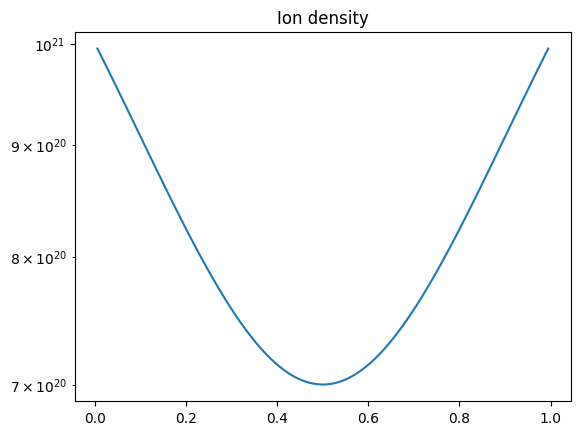

In [83]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 100

t_final = 1.0e-4
# t_final = 1.0e-5

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.4

# ion_density = np.logspace(20, 21, n_cells)
ion_density = 1.0e21 - 3.0e20 * np.sin(math.pi * x_center)

ion_velocity = np.zeros(n_cells)

ion_temperature = np.zeros(n_cells)
ion_temperature[:] = 1.0

def get_index(x):
    return int(x * n_cells)

def get_BGK_stddev(T):
    return np.sqrt(T * 1.602176634e-19 / 1.67e-27)

def get_collision_rate(T, dens):
    return 3.2e-15 * np.sqrt(T/0.026) * dens

plt.figure()
plt.semilogy(x_center, ion_density)
plt.title('Ion density')

In [84]:
## Calculate reference solution using eigrene

import subprocess
import json

config = {}

config["mesh"] = {
    "type": "voxel",
    "Lx": 1,
    "Ly": 1,
    "Lz": 1,
    "nx": n_cells,
    "ny": 1,
    "nz": 1,
}

config["background"] = {
    "plasma_dens": ion_density.tolist(),
    "plasma_temp": ion_temperature.tolist(),
    "plasma_vel_x": ion_velocity.tolist(),
    "plasma_vel_y": np.zeros(n_cells, dtype=np.float64).tolist(),
    "plasma_vel_z": np.zeros(n_cells, dtype=np.float64).tolist(),
}

x0_index = get_index(x0)
bgk_stddev = get_BGK_stddev(ion_temperature[x0_index])
x0_velocity = ion_velocity[x0_index]
config["sources"] = [
    {
        "type": "point",
        "n_particles": 1000000,
        "intensity": 1.0,
        "pos": [x0, 0.5, 0.5],
        "vel_mean": [x0_velocity, 0, 0],
        "vel_stddev": bgk_stddev,
    },
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
]

config["t_final"] = t_final
config["max_steps"] = 10000000
config["seed"] = 0


inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

subprocess.check_output(["../build/main_json"]).decode("utf-8")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

density_reference = np.array(output["density"])

{'grid_building_time': 1.1455e-05, 'num_collisions': 1420122360, 'num_crossings': 79430941, 'total_time': 47.750172097, 'trace_time': 47.750160642}


In [85]:
## Simple KD simulation

n_particles = 100000
density_kd = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_kd = 1.0e-5

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: simulate fluidly until the next collision
        #
        t_diffusive = t_next - t

        if(t_diffusive > 0):

            # draw next position from analytical solution
            drift_term = ion_velocity[x_index] * t_diffusive

            Rcx = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            Rcxtheta = Rcx * t_diffusive
            D = get_BGK_stddev(ion_temperature[x_index])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
            if(D < 0):
                D = 0
            D = np.sqrt(2. * D * t_diffusive)
            diffusion_term = D * np.random.normal(0, 1)

            x_particle_new = x_particle + drift_term + diffusion_term
            # check if we are outside the domain
            # if so, reflect, this should be correct as it results
            # in the same distribution as the method of images
            # which is exact in 1D
            if(x_particle_new < 0):
                x_particle_new = -x_particle_new
            if(x_particle_new > 1):
                x_particle_new = 1 - (x_particle_new - 1)

            x_index_new = get_index(x_particle_new)

            # Only accept new position if it is within the domain
            if x_index_new < 0 or x_index_new >= n_cells:
                continue

            x_particle = x_particle_new
            x_index = x_index_new
            t += t_diffusive

    # tally final position
    volume = 1/(n_cells)
    density_kd[x_index] += 1/volume / n_particles

In [86]:
## KD simulation, but with smaller fluid timesteps

n_particles = 100000
density_kd3 = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_kd = 1.0e-5
dt_fluidsteps = 1.0e-5


for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: simulate fluidly until the next collision
        #
        t_diffusive = t_next - t

        if(t_diffusive > 0):

            while(t < t_next):
                dt_fluidsteps2 = min(dt_fluidsteps, t_next - t)

                # draw next position from analytical solution
                drift_term = ion_velocity[x_index] * dt_fluidsteps2

                Rcx = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
                Rcxtheta = Rcx * t_diffusive
                D = get_BGK_stddev(ion_temperature[x_index])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
                if(D < 0):
                    D = 0
                D = np.sqrt(2. * D * dt_fluidsteps2)
                diffusion_term = D * np.random.normal(0, 1)

                x_particle_new = x_particle + drift_term + diffusion_term
                # check if we are outside the domain
                # if so, reflect, this should be correct as it results
                # in the same distribution as the method of images
                # which is exact in 1D
                if(x_particle_new < 0):
                    x_particle_new = -x_particle_new
                if(x_particle_new > 1):
                    x_particle_new = 1 - (x_particle_new - 1)

                x_index_new = get_index(x_particle_new)

                # # Only accept new position if it is within the domain
                # if x_index_new < 0 or x_index_new >= n_cells:
                #     continue

                x_particle = x_particle_new
                x_index = x_index_new
                t += dt_fluidsteps2

    # tally final position
    volume = 1/(n_cells)
    density_kd3[x_index] += 1/volume / n_particles

In [89]:
## KD with runge-kutta simulation of the fluid part

n_particles = 10000000
density_kd_rk = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_kd = 1.0e-5

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: simulate fluidly until the next collision
        #
        t_diffusive = t_next - t

        if(t_diffusive > 0):

            W = np.random.normal(0, 1) * np.sqrt(t_diffusive)
            s = 1. if np.random.rand() < 0.5 else -1.

            # calculate K1


            drift_term = ion_velocity[x_index]
            Rcx = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            Rcxtheta = Rcx * t_diffusive
            D = get_BGK_stddev(ion_temperature[x_index])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
            if(D < 0):
                D = 0
            D = np.sqrt(2. * D)
            diffusion_term = D

            K1 = drift_term * t_diffusive + (W - s * np.sqrt(t_diffusive)) * diffusion_term

            # Calculate intermediate position

            x_temp = x_particle + K1
            if(x_temp < 0):
                x_temp = -x_temp
            if(x_temp > 1):
                x_temp = 1 - (x_temp - 1)

            x_index_temp = get_index(x_temp)

            # Calculate K2

            drift_term = ion_velocity[x_index_temp]
            Rcx = get_collision_rate(ion_temperature[x_index_temp], ion_density[x_index_temp])
            Rcxtheta = Rcx * t_diffusive
            D = get_BGK_stddev(ion_temperature[x_index_temp])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
            if(D < 0):
                D = 0
            D = np.sqrt(2. * D)
            diffusion_term = D

            K2 = drift_term * t_diffusive + (W + s * np.sqrt(t_diffusive)) * diffusion_term

            # Combine K1 and K2 to get new position

            x_particle_new = x_particle + 0.5 * (K1 + K2)
            # check if we are outside the domain
            # if so, reflect, this should be correct as it results
            # in the same distribution as the method of images
            # which is exact in 1D
            if(x_particle_new < 0):
                x_particle_new = -x_particle_new
            if(x_particle_new > 1):
                x_particle_new = 1 - (x_particle_new - 1)

            x_index_new = get_index(x_particle_new)

            x_particle = x_particle_new
            x_index = x_index_new
            t += t_diffusive

    # tally final position
    volume = 1/(n_cells)
    density_kd_rk[x_index] += 1/volume / n_particles

Text(0.5, 1.0, 'Density error at t=1e-4')

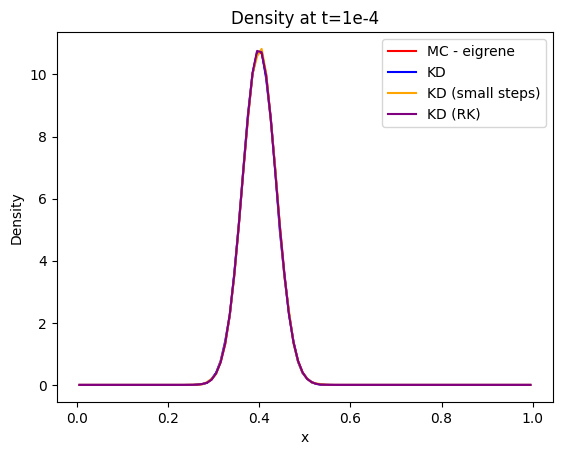

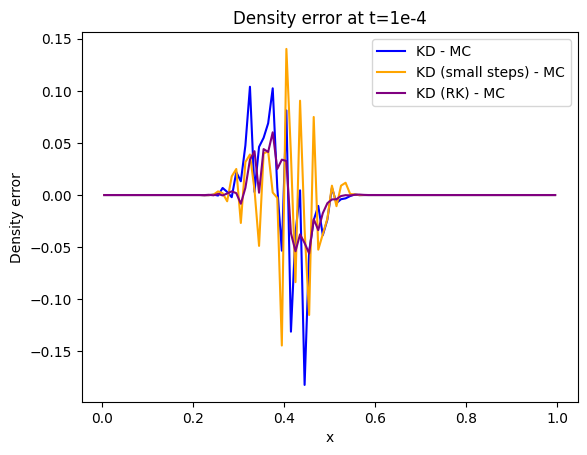

In [90]:
plt.figure()
# plt.plot(x_center, density_mc, label='MC - python', color='green')
plt.plot(x_center, density_reference, label='MC - eigrene', color='red')
plt.plot(x_center, density_kd, label='KD', color='blue')
plt.plot(x_center, density_kd3, label='KD (small steps)', color='orange')
plt.plot(x_center, density_kd_rk, label='KD (RK)', color='purple')
plt.legend()
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Density at t=1e-4')

plt.figure()
plt.plot(x_center, density_kd - density_reference, label='KD - MC', color='blue')
plt.plot(x_center, density_kd3 - density_reference, label='KD (small steps) - MC', color='orange')
plt.plot(x_center, density_kd_rk - density_reference, label='KD (RK) - MC', color='purple')
plt.legend()
plt.xlabel('x')
plt.ylabel('Density error')
plt.title('Density error at t=1e-4')